# Model basics: where do "model parameters" come from?

In the previous regression lecture we fit `realinc ~ educ` and calculated two numbers: an intercept of about −$14,000 and a slope of about $3,600. Today we will discover where those numbers came from.

This lesson is adapted from Chapter 23, "Model basics", of:

> Wickham, H. & Grolemund, G. *R for Data Science.* <https://r4ds.had.co.nz/model-basics.html>

Licensed CC BY-NC-ND 3.0 US. The original uses simulated data (`sim1`). We use our GSS data instead.

## Setup

In [1]:
library('tidymodels')

options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

── Attaching packages ────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ───────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Search for functions across packages at https://www.tidymodels.org/find/


## The data

Load the GSS data set from the regression lecture and drop the rows with missing values.

In [2]:
gss = read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss <- gss |> drop_na(realinc, educ)

gss |> glimpse()

Rows: 67,731
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


If we plot every person, the points pile up on top of each other (i.e. there is lots of overplotting). `geom_jitter()` moves the points around a bit and `alpha` makes them transparent. Together, they show the trend in the data.

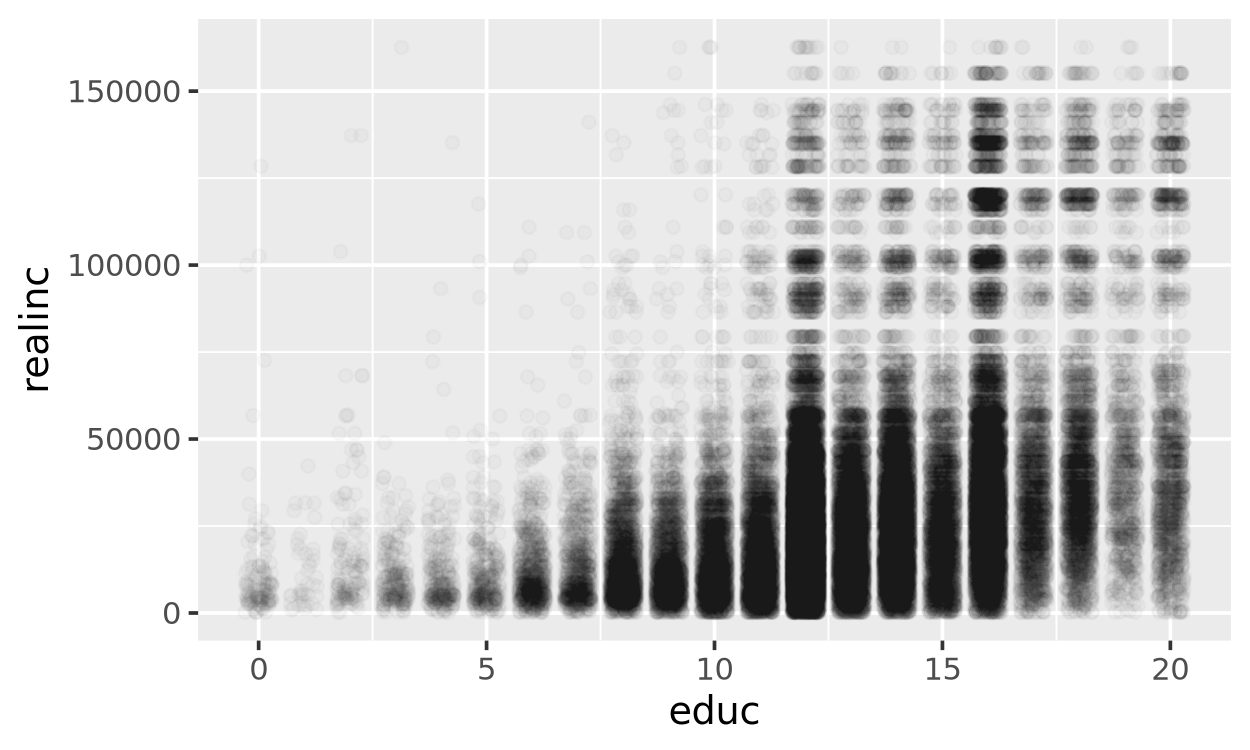

In [3]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_jitter(alpha = 0.02, width = 0.3)

Still hard to see. For visualization in this notebook, we'll plot the **mean** income at each education level. 

**The model we create will still use every data point, not just the mean value for each education level**.

In [4]:
income_by_educ <- gss |>
    group_by(educ) |>
    summarize(realinc = mean(realinc))

income_by_educ |> head()

  educ realinc 
1 0    11642.46
2 1    12030.38
3 2    18330.32
4 3    11435.07
5 4    11648.34
6 5    12475.96

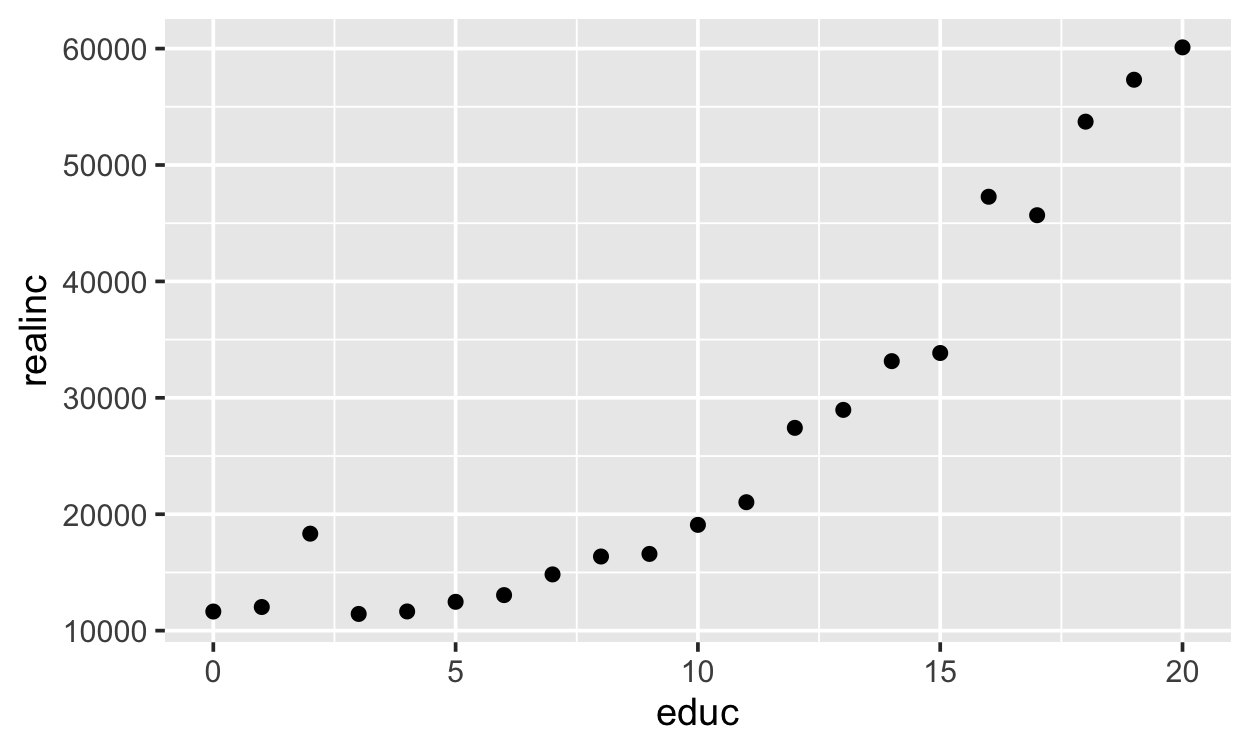

In [5]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) + geom_point()

## A model family

Let's "fit" a line to the data. A line takes the form:

$$ \text{realinc} = a_1 + a_2 \times \text{educ} $$

- $a_1$ is the **intercept**. It moves the line up and down.
- $a_2$ is the **slope**. It tilts the line.

But, what values should we use for $a_1$ and $a_2$? Let's start by guessing. We'll make 250 random combinations.

In [5]:
set.seed(512)

models <- tibble(
    a1 = runif(250, -40000, 40000),
    a2 = runif(250, -5000, 10000)
)

models |> head()

  a1         a2        
1  -9173.383   598.0216
2 -29290.667 -2076.9564
3  -3459.260  9205.7161
4  34594.730  3199.3232
5  11499.913  2164.0763
6 -24210.921  6572.8802

`geom_abline()` draws a line from an intercept and a slope.

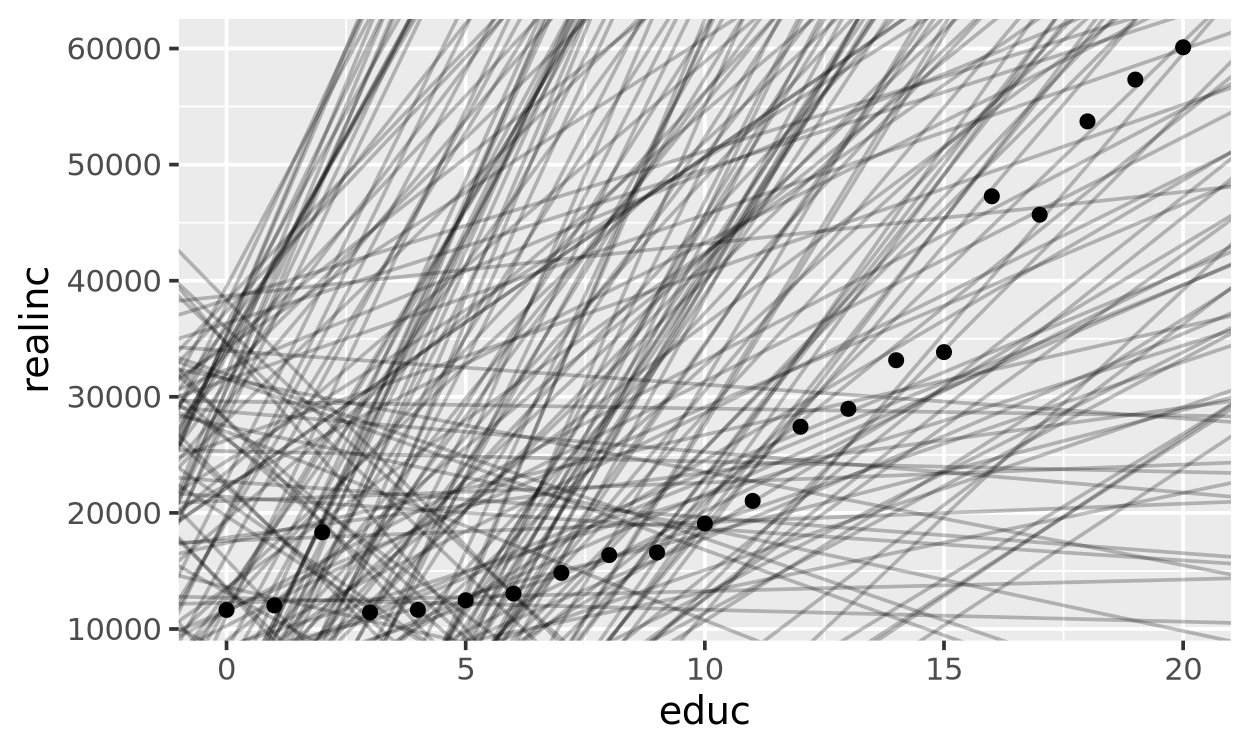

In [6]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(aes(intercept = a1, slope = a2), data = models, alpha = 0.25) +
    geom_point()

Most of these are terrible. A few are OK. **How do we say which line is best with a number?**

## Distance between a model and the data

Start with one "model" or *combination* of $a_1$ and $a_2$. For each person the model **predicts** `realinc`. The gap between a person's actual income and what the model predicted is the **residual**.

Let's write the model as a function. `a` is a vector with our two numbers.

In [7]:
model1 <- function(a, data) {
    a[1] + data$educ * a[2]
}

model1(c(-5000, 3000), income_by_educ)

 [1] -5000 -2000  1000  4000  7000 10000 13000 16000 19000 22000 25000 28000
[13] 31000 34000 37000 40000 43000 46000 49000 52000 55000

Here is what those gaps look like for the line $a_1 = -5000$, $a_2 = 3000$. Each red segment is one residual.

**Remember we are using the mean values by education level for visualization. Our actual model calculates the residual for every person in the data set!**

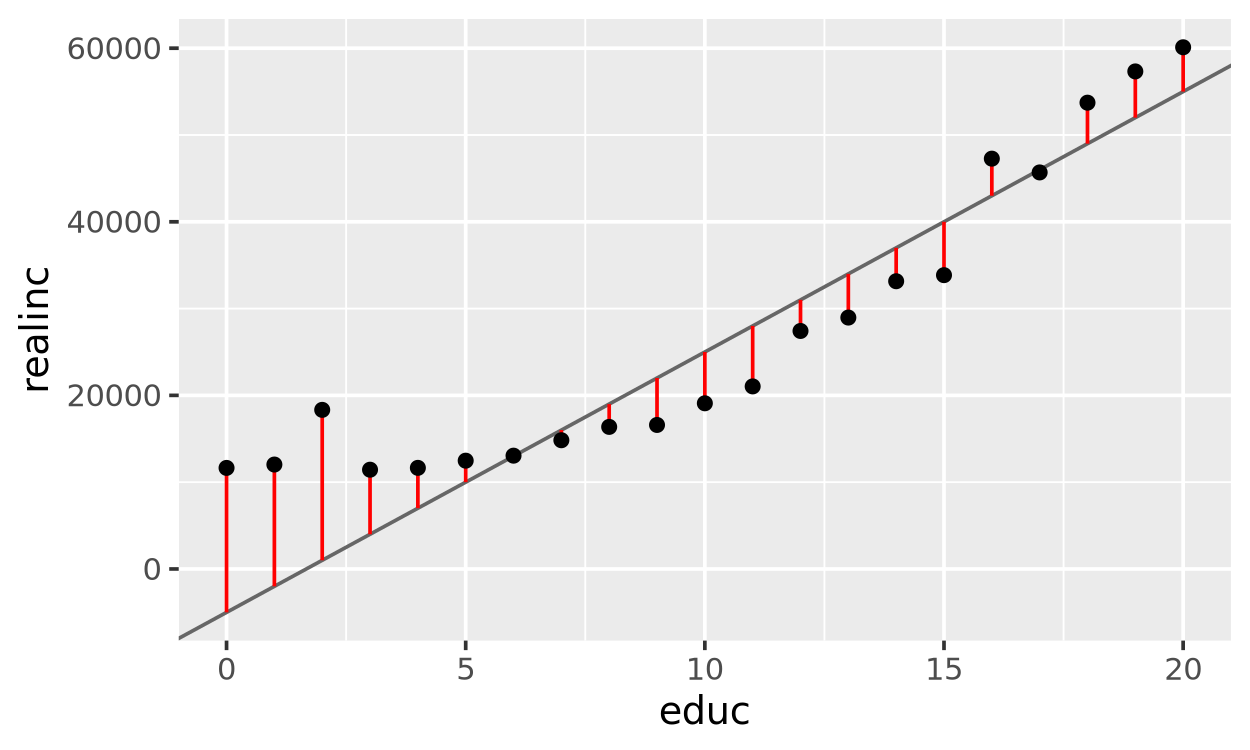

In [8]:
income_by_educ |>
    mutate(pred = model1(c(-5000, 3000), income_by_educ)) |>
ggplot(aes(x = educ)) +
    geom_abline(intercept = -5000, slope = 3000, color = 'grey40') +
    geom_segment(aes(y = realinc, yend = pred), color = 'red') +
    geom_point(aes(y = realinc))

Let's pick a number that measures how well the model predicts `realinc`, not 67,000 numbers. We'll use the **root mean squared error** (RMSE):

1. Get each residual: $\text{actual} - \text{predicted}$.
2. **Square** them so all individual values are positive.
3. Take the **mean**.
4. Take the square **root**. Now the units are dollars again.

$$ \text{RMSE} = \sqrt{\frac{1}{n} \sum (\text{actual} - \text{predicted})^2} $$

In [9]:
measure_distance <- function(mod, data) {
    diff <- data$realinc - model1(mod, data)
    sqrt(mean(diff ^ 2))
}

measure_distance(c(-5000, 3000), gss)

[1] 28421.63

That line misses by about $28,000 on a typical person. Smaller is better.

**You do:** pick your own $a_1$ and $a_2$. Can you beat that distance?

In [10]:
measure_distance(c(-15000, 3600), gss)

[1] 28300.75

## Score all 250 models

`measure_distance()` takes one model at a time. `map2_dbl()` from **purrr** runs it once for each row of `models`. It walks down `a1` and `a2` together and returns $\text{RMSE}$ for each pair.

In [11]:
gss_dist <- function(a1, a2) {
    measure_distance(c(a1, a2), gss)
}

models <- models |>
    mutate(dist = map2_dbl(a1, a2, gss_dist))

models |> arrange(dist) |> head()

  a1          a2       dist    
1 -11784.8668 3301.585 28328.10
2 -18773.1984 3967.549 28339.56
3    442.4071 2410.560 28541.08
4 -29549.6118 4841.924 28623.94
5   8217.2376 2038.907 28819.50
6 -32283.5692 5173.781 28923.82

Plot the 10 best. The lighter the line, the bigger the distance.

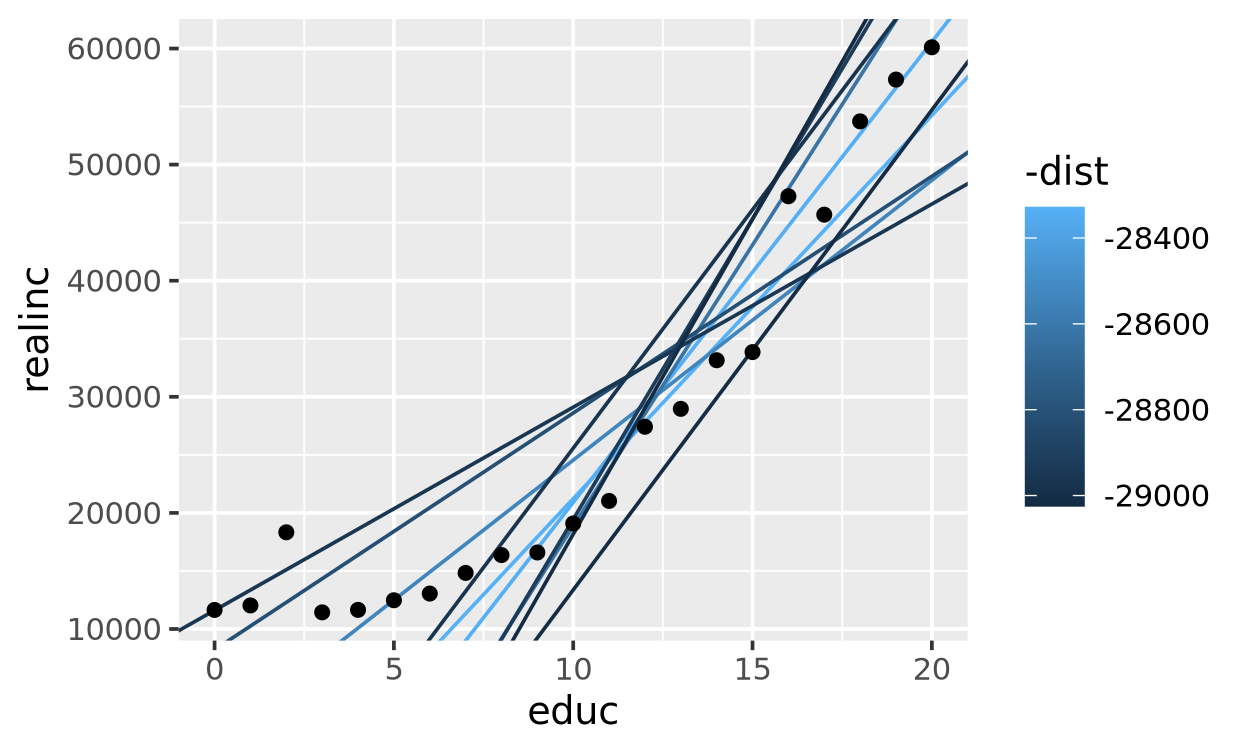

In [12]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(
        aes(intercept = a1, slope = a2, color = -dist),
        data = models |> slice_min(dist, n = 10)
    ) +
    geom_point()

### Models as points

Each model is just two numbers. So we can draw each model as a **point**, with $a_1$ on the x-axis and $a_2$ on the y-axis. Color by distance and circle the 10 best in red.

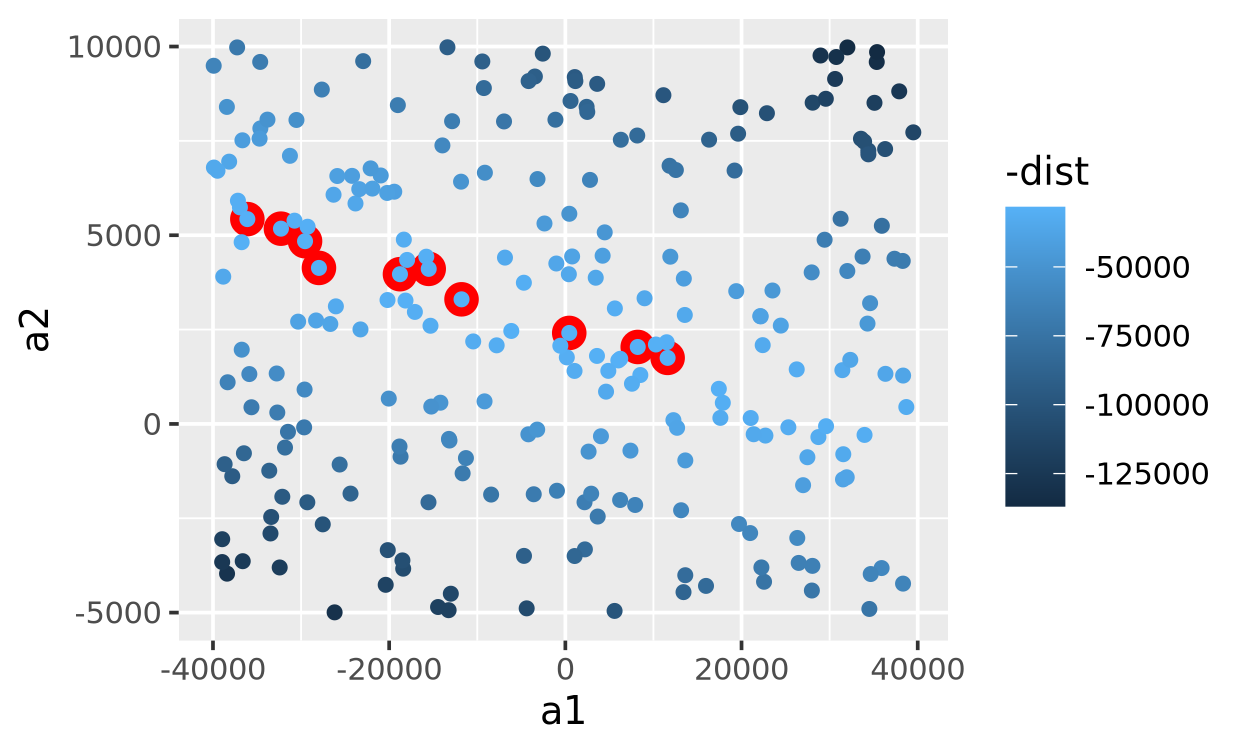

In [13]:
ggplot(models, aes(x = a1, y = a2)) +
    geom_point(data = models |> slice_min(dist, n = 10), size = 4, color = 'red') +
    geom_point(aes(color = -dist))

The good models are all in one spot. They are not spread out at random. Notice they follow a diagonal band: a lower intercept can make up for a steeper slope.

## Grid search

Random guessing is wasteful. Let's be smarter. Make an even **grid** of points around where the best models are, and score every one.

`expand_grid()` makes every combination, like in the regression lecture.

In [15]:
grid <- expand_grid(
    a1 = seq(-25000, -5000, length = 25),
    a2 = seq(2500, 4500, length = 25)
) |>
    mutate(dist = map2_dbl(a1, a2, gss_dist))

grid |> arrange(dist) |> head()

  a1        a2       dist    
1 -13333.33 3500.000 28301.22
2 -15833.33 3666.667 28301.81
3 -14166.67 3583.333 28302.72
4 -15000.00 3583.333 28303.15
5 -12500.00 3416.667 28304.59
6 -16666.67 3750.000 28305.35

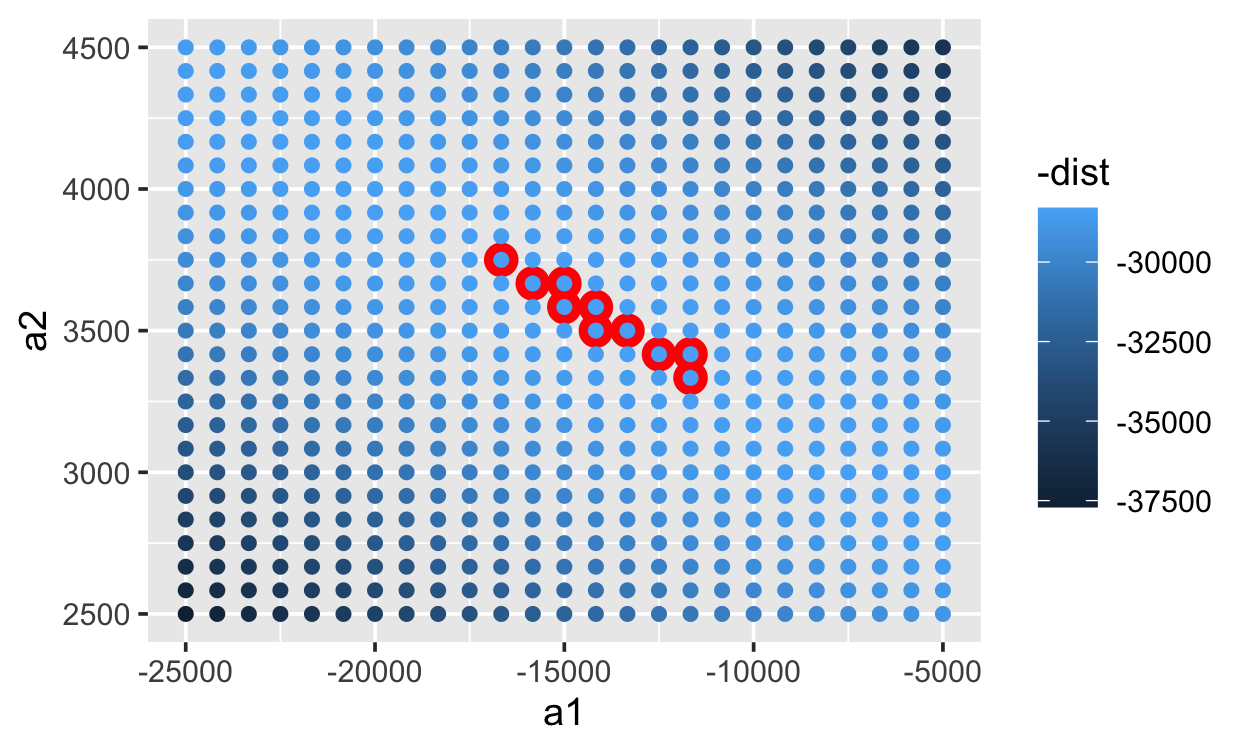

In [16]:
ggplot(grid, aes(x = a1, y = a2)) +
    geom_point(data = grid |> slice_min(dist, n = 10), size = 4, color = 'red') +
    geom_point(aes(color = -dist))

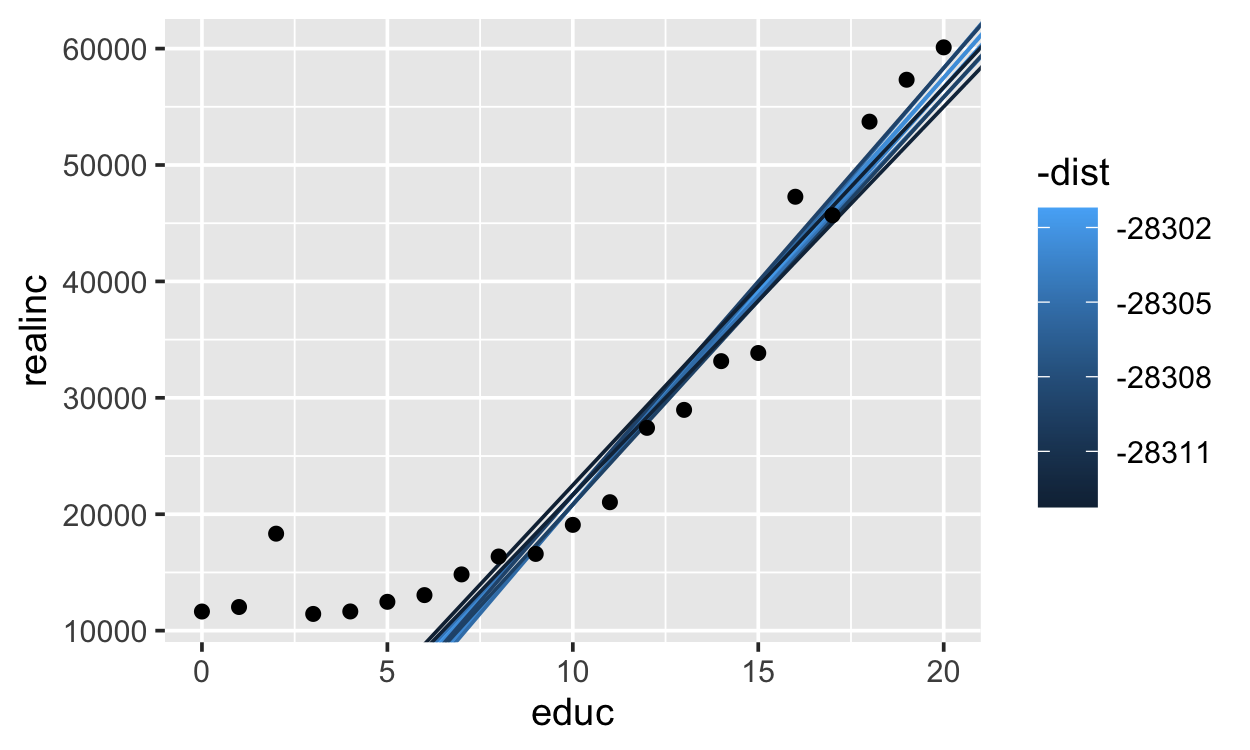

In [17]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(
        aes(intercept = a1, slope = a2, color = -dist),
        data = grid |> slice_min(dist, n = 10)
    ) +
    geom_point()

The 10 best lines are almost on top of each other now. We could keep making the grid finer and finer until we zoom in on the best model.

## Let the computer search

There is a better way. `optim()` is a general **optimizer**. Give it:

- a starting guess
- an *objective* to minimize, in our case this is `measure_distance`
- anything else that the "objective" function needs (like the data: `data = gss`)

It makes a guess and checks the objective. If the objective goes down, it keeps making intelligent guesses while the objective goes downhill until it can't optimize any further.

For the starting guess, use our best random model.

In [18]:
start <- models |> slice_min(dist, n = 1)

start

  a1        a2       dist   
1 -11784.87 3301.585 28328.1

In [19]:
best <- optim(c(start$a1, start$a2), measure_distance, data = gss)

best$par

[1] -14493.137   3577.444

In [20]:
best$value

[1] 28299.86

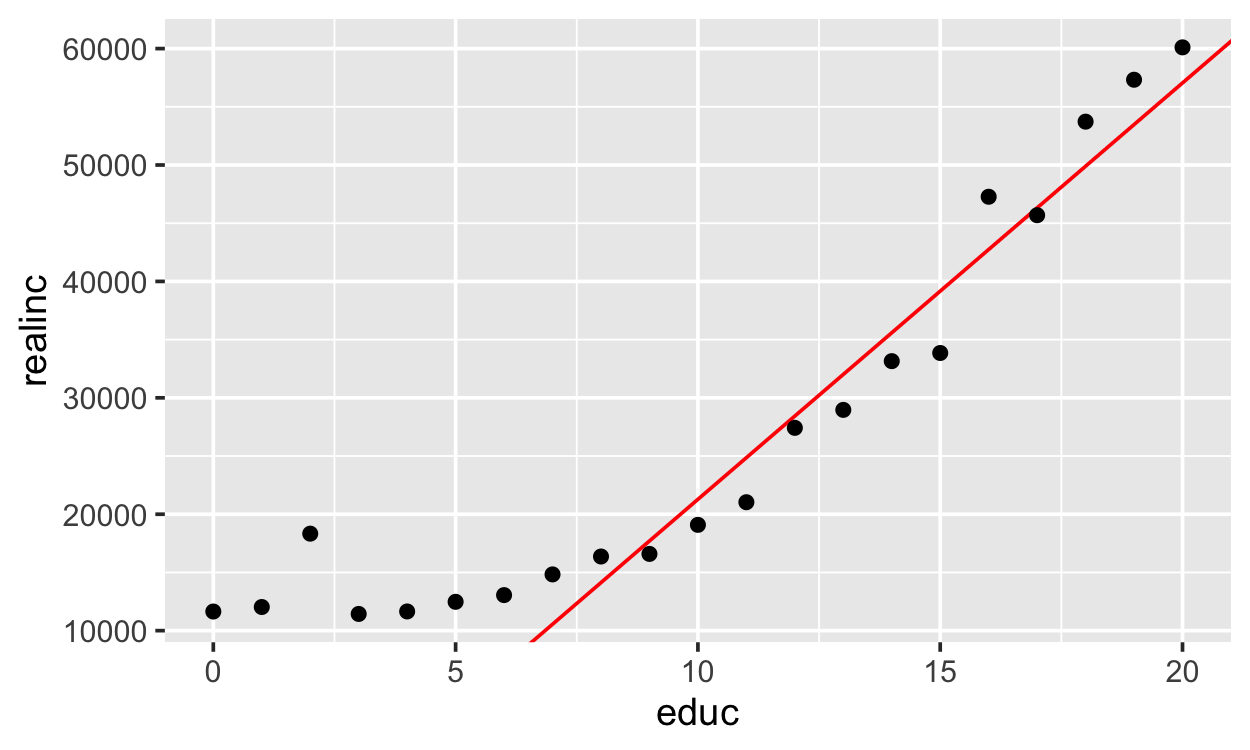

In [21]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(intercept = best$par[1], slope = best$par[2], color = 'red') +
    geom_point()

**You do:** start `optim()` at `c(0, 0)` instead. What happens?

<details>
<summary>Answer</summary>

```r
optim(c(0, 0), measure_distance, data = gss)$par
```

It stops too early, at a worse model. Remember the diagonal band in the plot above? The ground is almost flat along it, so `optim()` thinks it is done. A good starting guess matters.

</details>

In [22]:
optim(c(0, 0), measure_distance, data = gss)$par

[1]  464.5525 2500.3898

### Watch the search

`optim()` tries many models on its way down. Let's write down every one.

`measure_distance_log()` does the same job as `measure_distance()`. It also adds a row to `path` for each model it scores. The `<<-` saves to `path` outside the function.

In [23]:
path <- tibble()

measure_distance_log <- function(mod, data) {
    dist <- measure_distance(mod, data)
    path <<- bind_rows(path, tibble(a1 = mod[1], a2 = mod[2], dist = dist))
    dist
}

Run `optim()` from our best random model. Then number the steps.

In [24]:
path <- tibble()

optim(c(start$a1, start$a2), measure_distance_log, data = gss)$par

path_good <- path |> mutate(step = row_number(), start = 'best random model')

path_good |> head()

  a1        a2       dist     step start            
1 -11784.87 3301.585 28328.10 1    best random model
2 -10606.38 3301.585 28314.28 2    best random model
3 -11784.87 4480.071 31961.34 3    best random model
4 -10606.38 2123.098 32468.87 4    best random model
5 -11490.25 3890.828 29199.34 5    best random model
6 -10901.00 2712.341 29477.98 6    best random model

To see the hills and valleys, score a fine grid of models and draw **contour** lines. Each line connects models with the same distance, like a map of a mountain.

In [25]:
surface <- expand_grid(
    a1 = seq(-25000, 5000, length = 60),
    a2 = seq(0, 5000, length = 60)
) |>
    mutate(dist = map2_dbl(a1, a2, gss_dist))

We want more lines near the bottom of the valley, so we can see its shape. Start at the smallest distance and double the gap each time: 100, 200, 400, ...

In [26]:
levels <- min(surface$dist) + 100 * 2^(0:10)

levels

 [1]  28399.99  28499.99  28699.99  29099.99  29899.99  31499.99  34699.99
 [8]  41099.99  53899.99  79499.99 130699.99

Now draw the path from our best random model on the map. Each point is one model `optim()` tried.

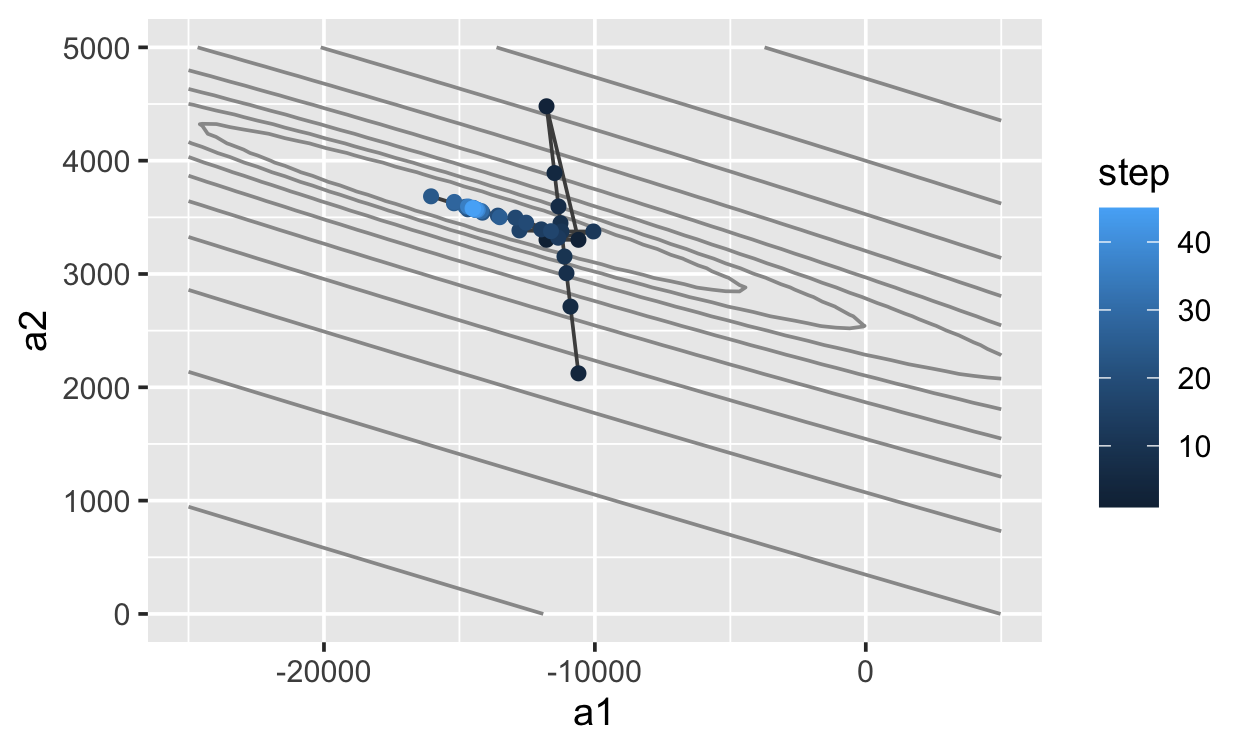

In [27]:
ggplot(path_good, aes(x = a1, y = a2)) +
    geom_contour(aes(z = dist), data = surface, breaks = levels, color = 'grey60') +
    geom_path(color = 'grey30') +
    geom_point(aes(color = step))

The valley is long and thin. `optim()` starts in the middle of it. It tries steps up and down, then walks left along the valley floor to the best model.

`optim()` does not care that our model is a line. It works for **any** function we can write that returns a distance. That is the big idea:

1. Pick a **form** for your model.
2. Pick a way to **measure** the "fit" from the data.
3. **Search** for the $a_1$ and $a_2$ with the best fit.

## Compare with `linear_reg()`

Now fit the model the way we did in the regression lecture.

In [28]:
fit1 <- linear_reg() |> fit(realinc ~ educ, data = gss)

fit1

parsnip model object


Call:
stats::lm(formula = realinc ~ educ, data = data)

Coefficients:
(Intercept)         educ  
     -14472         3576  


In [29]:
best$par

[1] -14493.137   3577.444

Same numbers! The tiny difference is because `optim()` stops when it is "close enough".


`linear_reg()` uses `lm()` under the hood. For straight-line models with this distance, there is a math shortcut that finds the exact answer in one step, no searching needed. That is why it is so fast. The name **least squares** comes from the objective function: *minimize the sum of the squared residuals.*

## Look at the predictions

`predict()` gives the model's guess for new data. Make a grid of education levels and predict.

In [30]:
grid_educ <- tibble(educ = 0:20)

preds <- fit1 |> predict(new_data = grid_educ) |> bind_cols(grid_educ)

preds |> head()

  .pred       educ
1 -14472.0096 0   
2 -10896.0428 1   
3  -7320.0761 2   
4  -3744.1093 3   
5   -168.1425 4   
6   3407.8243 5   

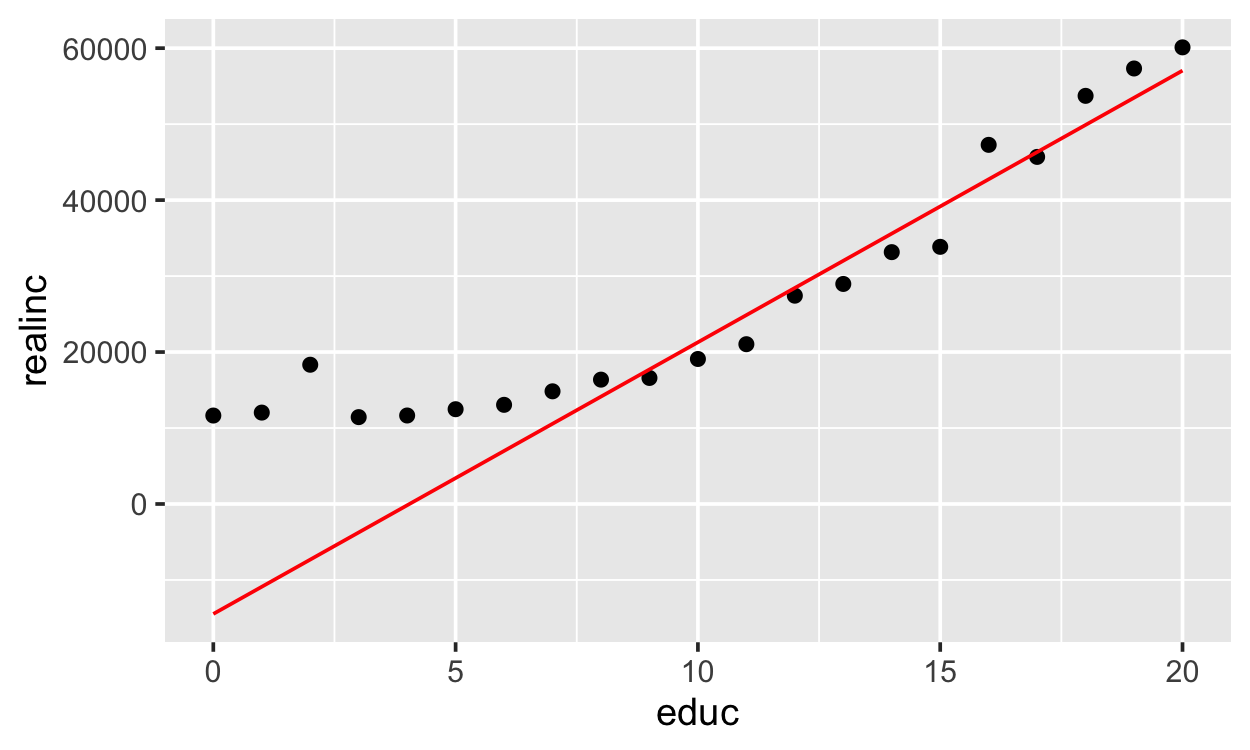

In [31]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_point() +
    geom_line(data = preds, aes(y = .pred), color = 'red')

## You do: a different distance

RMSE squares the residuals, so a few people with very high incomes pull hard on the line. Another choice is the **mean absolute error** (MAE): the mean of the absolute values of the residuals.

1. Write `measure_distance_mae()`. Use `abs()` in place of the square and square root.
2. Use `optim()` to find the best $a_1$ and $a_2$. Start at `best$par`.
3. Draw both lines over `income_by_educ`. How are they different?

<details>
<summary>Hint</summary>

```r
measure_distance_mae <- function(mod, data) {
    diff <- data$realinc - model1(mod, data)
    mean(abs(diff))
}
```

</details>

In [32]:
measure_distance_mae <- function(mod, data) {
    diff <- data$realinc - model1(mod, data)
    mean(abs(diff))
}

best_mae <- optim(best$par, measure_distance_mae, data = gss)

best_mae$par

[1] -8370.077  2563.523

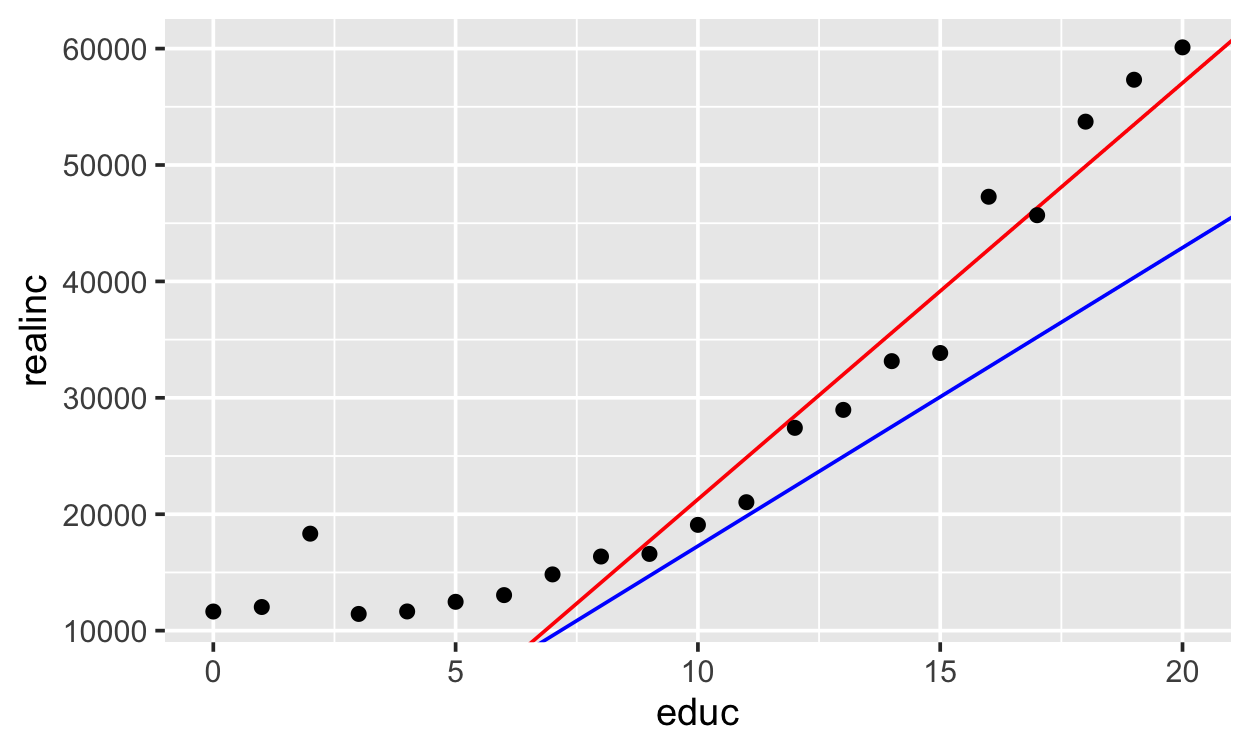

In [33]:
ggplot(income_by_educ, aes(x = educ, y = realinc)) +
    geom_abline(intercept = best$par[1], slope = best$par[2], color = 'red') +
    geom_abline(intercept = best_mae$par[1], slope = best_mae$par[2], color = 'blue') +
    geom_point()

The blue MAE line sits lower. Income is **skewed**: a few people earn a lot. Squaring gives those big misses more pull, so the RMSE line moves up toward them. MAE gives them less pull.

Same family, different distance, different "best" model. The numbers `tidy()` gives you depend on the distance you chose.